# Map for 2026 AGU poster

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import cartopy.crs as ccrs
import cartopy.io.img_tiles as cimgt
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

from scipy.stats import rankdata
from scipy.stats import ks_2samp
from sklearn.manifold import MDS

import cmcrameri.cm as cmc

from matplotlib import rc
rc("pdf", fonttype=42)

from geoscripts import maps
from geoscripts.dz import dz

In [12]:
sattelite = cimgt.GoogleTiles(
    url='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}'
    )

hillshade = cimgt.GoogleTiles(
    url='https://server.arcgisonline.com/ArcGIS/rest/services/Elevation/World_Hillshade/MapServer/tile/{z}/{y}/{x}'
    )


tect_map = gpd.read_file('../maps/morocco_tectonic_map.gpkg',layer='polygons_colored')

smps = dz.load_all('../dz/')

In [13]:
# Detrital zircon samples and provenance groups (from analysis_dz.ipynb)
smps_ptr = [smp for smp in smps if smp.reported_age=='P-Tr' 
            and smp.source not in ['Foster-Baril','VanTongeren']
            and smp.latlon[1]>-20
            and smp.bestage.count()>=100]

spans = [(200,300),(300,500),(500,750),(900,1400),(1600,2500),(2500,3500)]
colors = ['#215f60', '#faccfa', '#828231', '#011959', '#391400', '#f19c6b']

for smp in smps_ptr:
    smp.meseta = ((smp.bestage>=spans[0][0])&(smp.bestage<spans[0][1])).sum()/smp.bestage.count()
    smp.reguibat = ((smp.bestage>=spans[-1][0])&(smp.bestage<spans[-1][1])).sum()/smp.bestage.count()
    if smp.meseta>=0.03:
        smp.color = colors[0]
    elif smp.reguibat>=0.15:
        smp.color = colors[5]
    else:
        smp.color = 'lightgrey'

mr24_dict = {'MR24-006':'RH1','MR24-008':'JB2','MR24-009':'JB1','MR24-017':'JB3',
             'MR24-020':'MHA1','MR24-023':'MHA2'}

In [14]:
# Igneous samples (from analysis_igneous.ipynb)
smps_ig = [smp for smp in smps if smp.source=='VanTongeren' and smp.mda>200]

data = pd.read_csv('../published_data/Atlas_C-Tr_Ig_GchronCompilation_060126.csv',index_col=0)
data_ig = data[data['System']=='U-Pb'].copy()
data_ig[['Longitude (DD)', 'Latitude (DD)']] = data_ig[['Longitude (DD)', 'Latitude (DD)']].apply(pd.to_numeric, errors='coerce')

for smp in smps_ig:
    data_ig.loc[smp.name,['Latitude (DD)', 'Longitude (DD)']] = smp.latlon
    data_ig.loc[smp.name,'Age (Ma)'] = smp.mda

data_ig['New'] = data_ig['Source'].isna()

new_names_dict = {'MR24-012':'JBD2', 'MR24-013':'JBD3', 'MR24-015':'JBD4',
                  'MR24-016':'JBD5'}

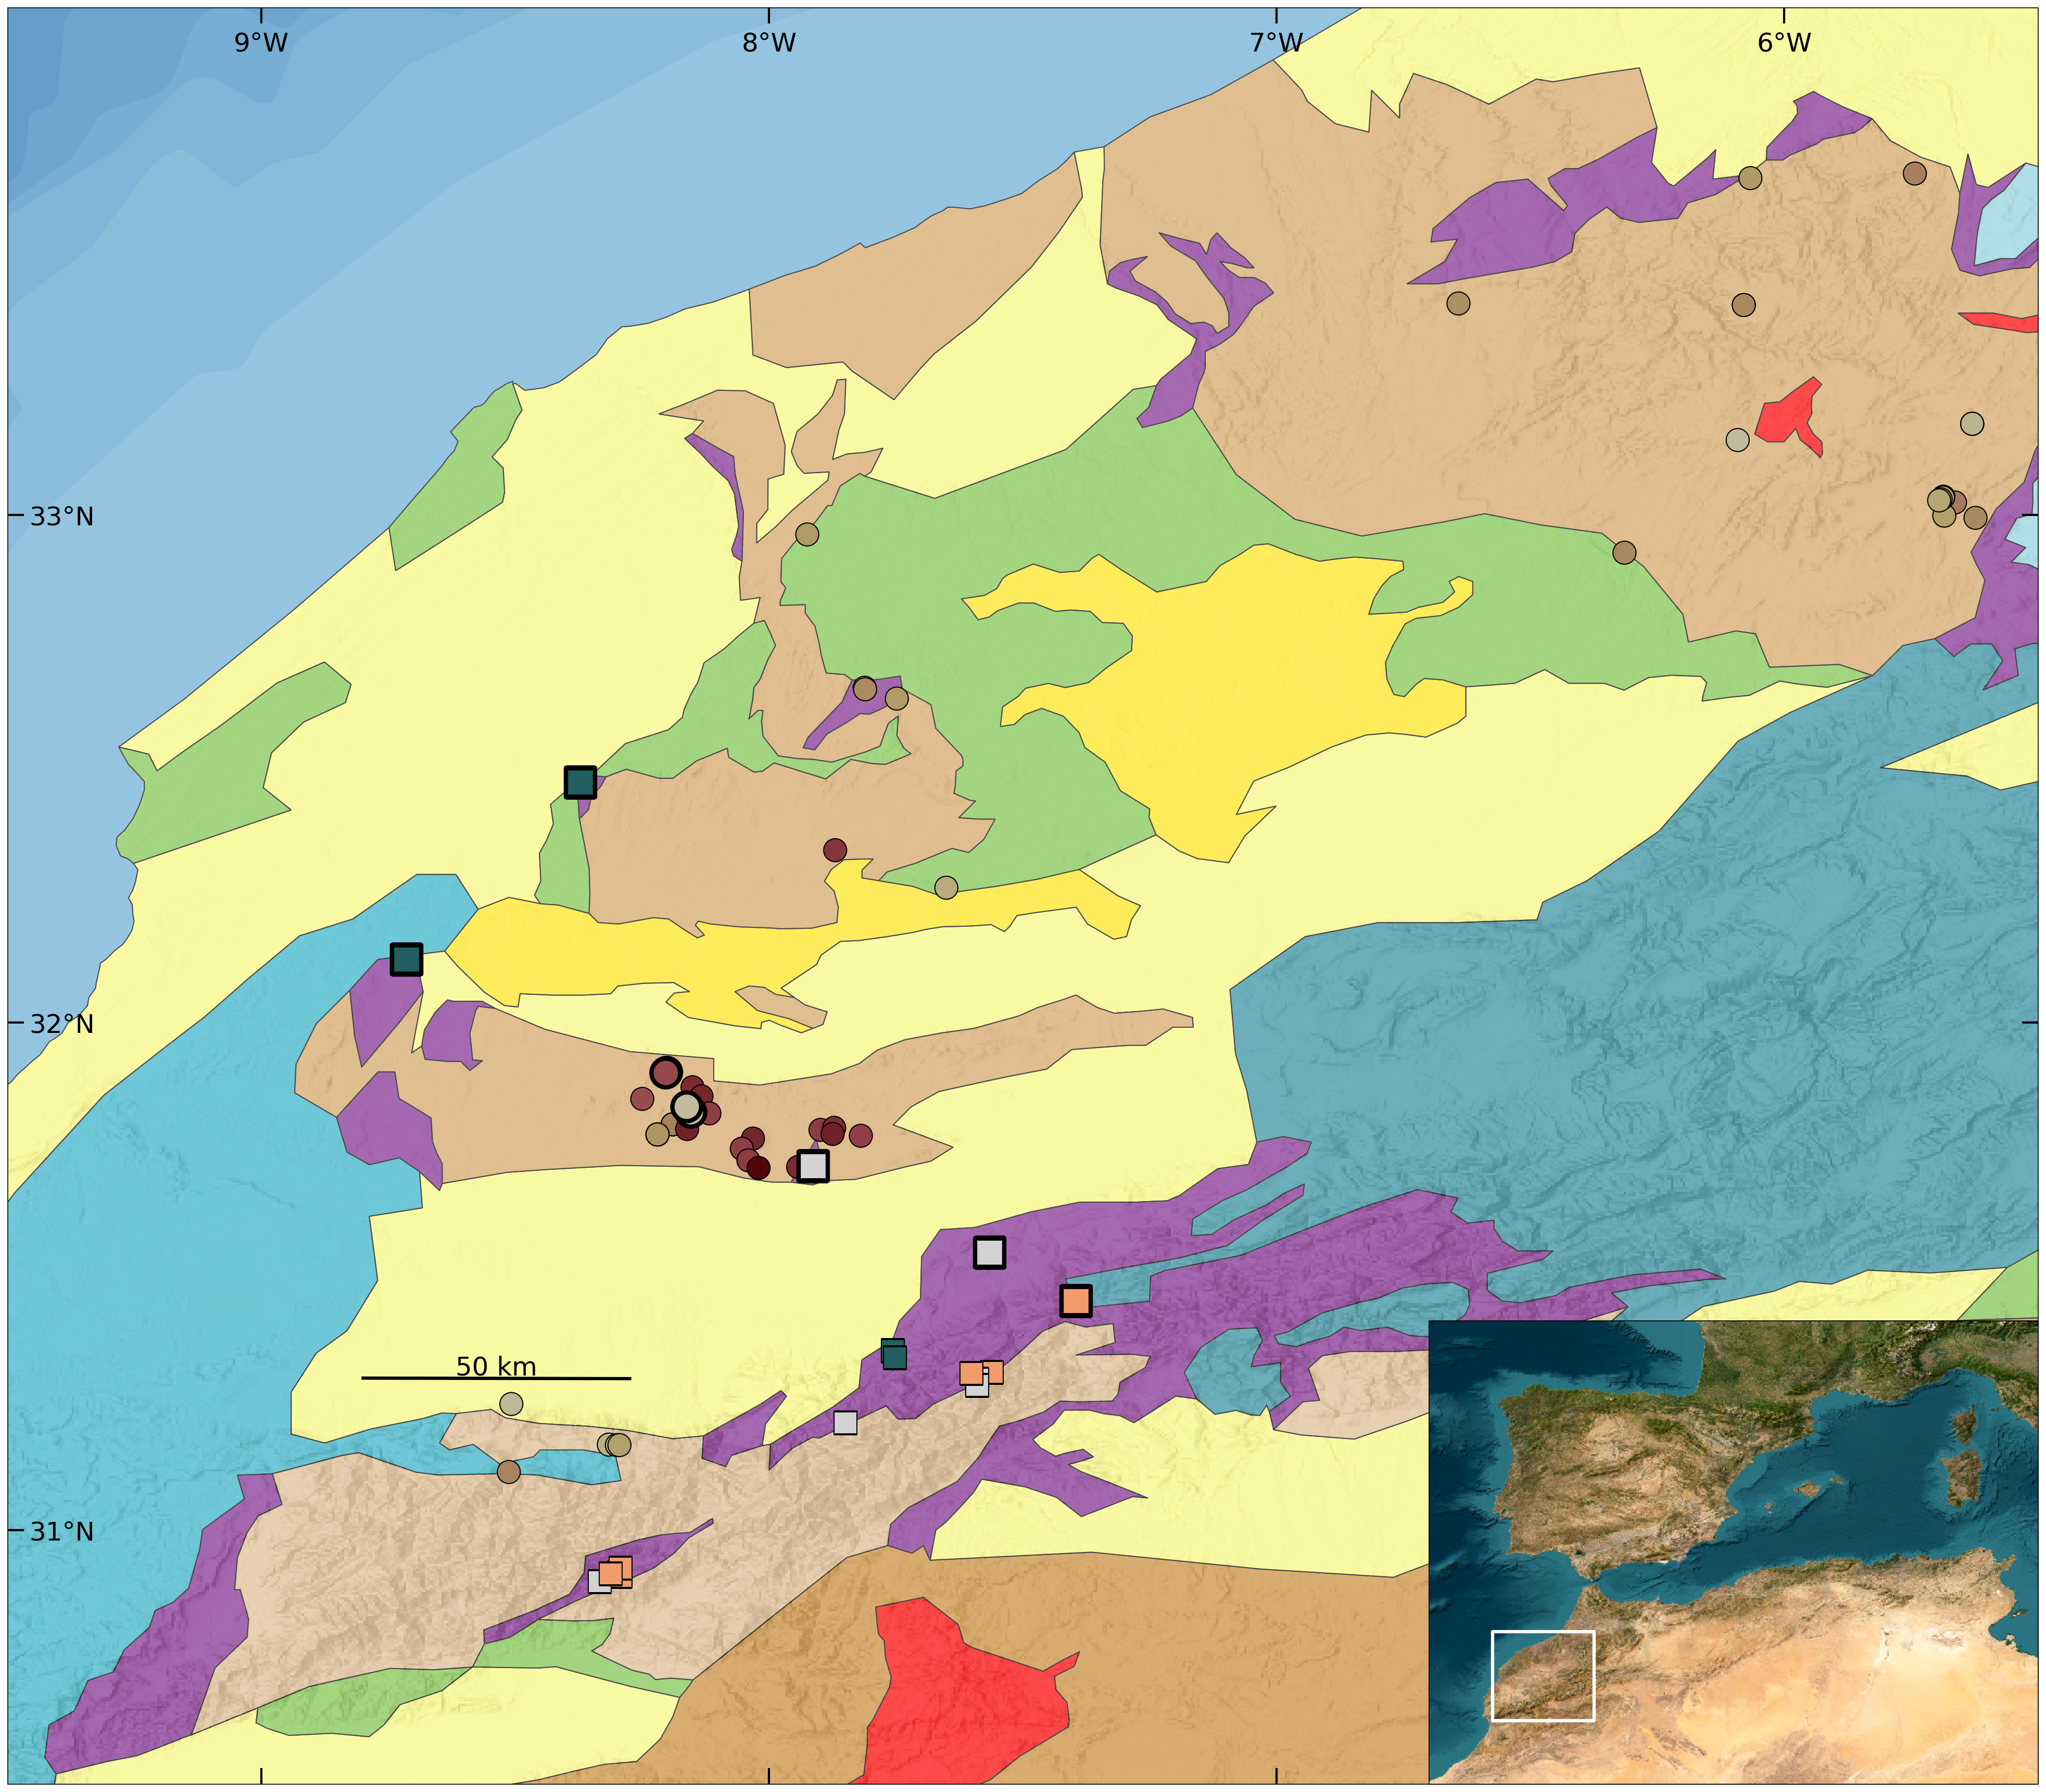

In [20]:
fs = 24  # Base font size for poster
cmap = cmc.bilbao_r
norm = plt.Normalize(vmin=240, vmax=360)

fig, ax = plt.subplots(1, figsize=(26,26), dpi=150,
                         subplot_kw={'projection':ccrs.PlateCarree()})
fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

ax.set_extent([-9.5,-5.5,30.5,34])
ax.set_facecolor(plt.cm.Blues(0.5))
ax.add_image(hillshade,9,alpha=0.3, zorder=1.5)
tect_map.plot(ax=ax,color=tect_map['unit_color'],alpha=1, zorder=1.1,
                edgecolor='black', linewidth=1)
maps.bath(ax=ax) 

ax.set_xticks(np.arange(-9, -5, 1))
ax.set_yticks(np.arange(31, 34, 1))
ax.xaxis.set_major_formatter(LongitudeFormatter())
ax.yaxis.set_major_formatter(LatitudeFormatter())

ax.tick_params(direction='in', length=15, width=2, labelsize=fs, top=True, right=True,
               labeltop=True, labelbottom=False, labelright=False)
ax.tick_params(axis='x', pad=-45)
ax.tick_params(axis='y', pad=-80)


maps.scalebar(length=50e3,color='black',ax=ax,slon=-8.8,slat=31.3)
ax.texts[-1].set_fontsize(fs)

for smp in smps_ptr:
    new = smp.source=='Vasey'
    ax.scatter(smp.latlon[1],smp.latlon[0],color=smp.color,marker='s',
               edgecolor='black',linewidth=4 if new else 1,s=700 if new else 450,zorder=4)
    #if new:
    #    ax.annotate(mr24_dict.get(smp.name,smp.name),(smp.latlon[1],smp.latlon[0]),
                    #xytext=(12,8),textcoords='offset points',fontsize=fs-4,fontweight='bold')

for new, group in data_ig.groupby('New'):
    sc = ax.scatter(group['Longitude (DD)'],group['Latitude (DD)'],c=group['Age (Ma)'],
                    cmap=cmap,norm=norm,marker='o',s=700 if new else 450,
                    edgecolor='black',linewidth=4 if new else 1,zorder=5 if new else 3)
#for smp in smps_ig:
    #ax.annotate(new_names_dict[smp.name],(smp.latlon[1],smp.latlon[0]),
    #            xytext=(12,-20),textcoords='offset points',fontsize=fs-4,fontweight='bold')

# Igneous age colorbar
#cax = ax.inset_axes([0.04,0.93,0.3,0.015])
#cbar = fig.colorbar(sc,cax=cax,orientation='horizontal')
#cbar.set_label('Igneous zircon U-Pb age (Ma)',fontsize=fs)
#cbar.ax.tick_params(labelsize=fs-4)

# Western Mediterranean inset
inset = ax.inset_axes([0.7,0.0,0.3,0.3], projection=ccrs.PlateCarree())
inset.set_anchor('SE')
inset.set_extent([-12,12,28,46])
inset.add_image(sattelite,5)
maps.bb_auto(ax,ax=inset,facecolor='none',edgecolor='white',linewidth=3)

fig.savefig('agu_map.pdf')

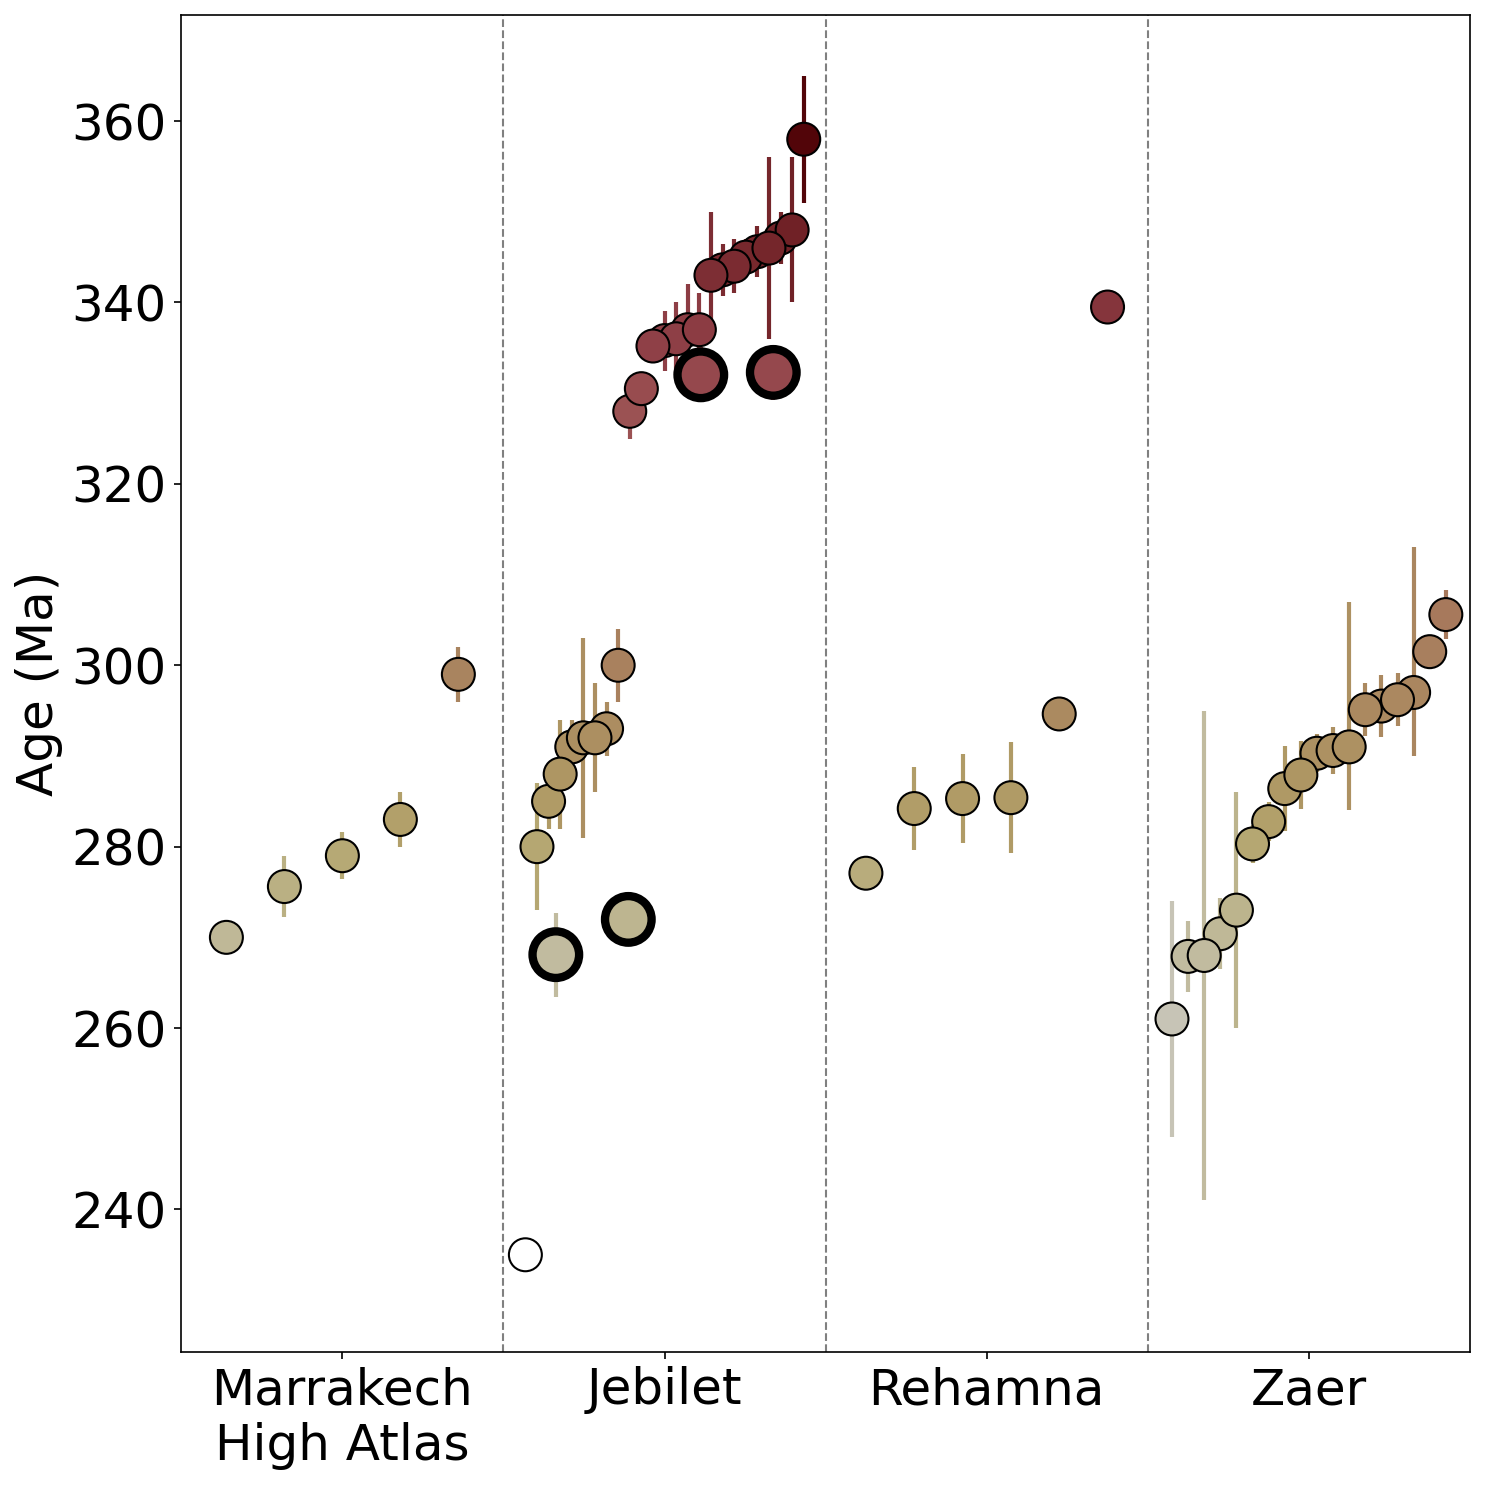

In [16]:
# Ranked-order igneous U-Pb ages by subregion

def rank_jitter(ages, width=0.9):
    ranks = rankdata(ages, method='ordinal')
    return (ranks - (len(ages) + 1) / 2) / len(ages) * width

for smp in smps_ig:
    data_ig.loc[smp.name, 'Error (Ma)'] = smp.mda_err
    data_ig.loc[smp.name, 'Subregion'] = 'Jebilet'

regions = ['Marrakech', 'Jebilet', 'Rehamna', 'Zaer']
labels = ['Marrakech\nHigh Atlas', 'Jebilet', 'Rehamna', 'Zaer']

fig, ax = plt.subplots(figsize=(10,10), dpi=150)
fig.subplots_adjust(left=0, right=1, bottom=0, top=1)

for i, region in enumerate(regions):
    group = data_ig[data_ig['Subregion']==region]
    # Rank new and published samples separately, as in the paper figure
    x = i + group.groupby('New')['Age (Ma)'].transform(lambda a: rank_jitter(a.values))
    lower = group['Lower Error (Ma)'].fillna(group['Error (Ma)'])
    ax.errorbar(x, group['Age (Ma)'], yerr=[lower, group['Error (Ma)']], fmt='none',
                ecolor=cmap(norm(group['Age (Ma)'])), elinewidth=2, zorder=2)
    ax.scatter(x, group['Age (Ma)'], c=group['Age (Ma)'], cmap=cmap, norm=norm, marker='o',
               s=np.where(group['New'], 500, 250), edgecolor='black',
               linewidths=np.where(group['New'], 4, 1), zorder=3)
    if i > 0:
        ax.axvline(i - 0.5, color='grey', linewidth=1, linestyle='--')

ax.set_xlim(-0.5, len(regions) - 0.5)
ax.set_xticks(range(len(regions)), labels)
ax.tick_params(axis='both', labelsize=fs)
ax.set_ylabel('Age (Ma)', fontsize=fs)

fig.tight_layout()
fig.savefig('agu_igneous_ages.pdf')

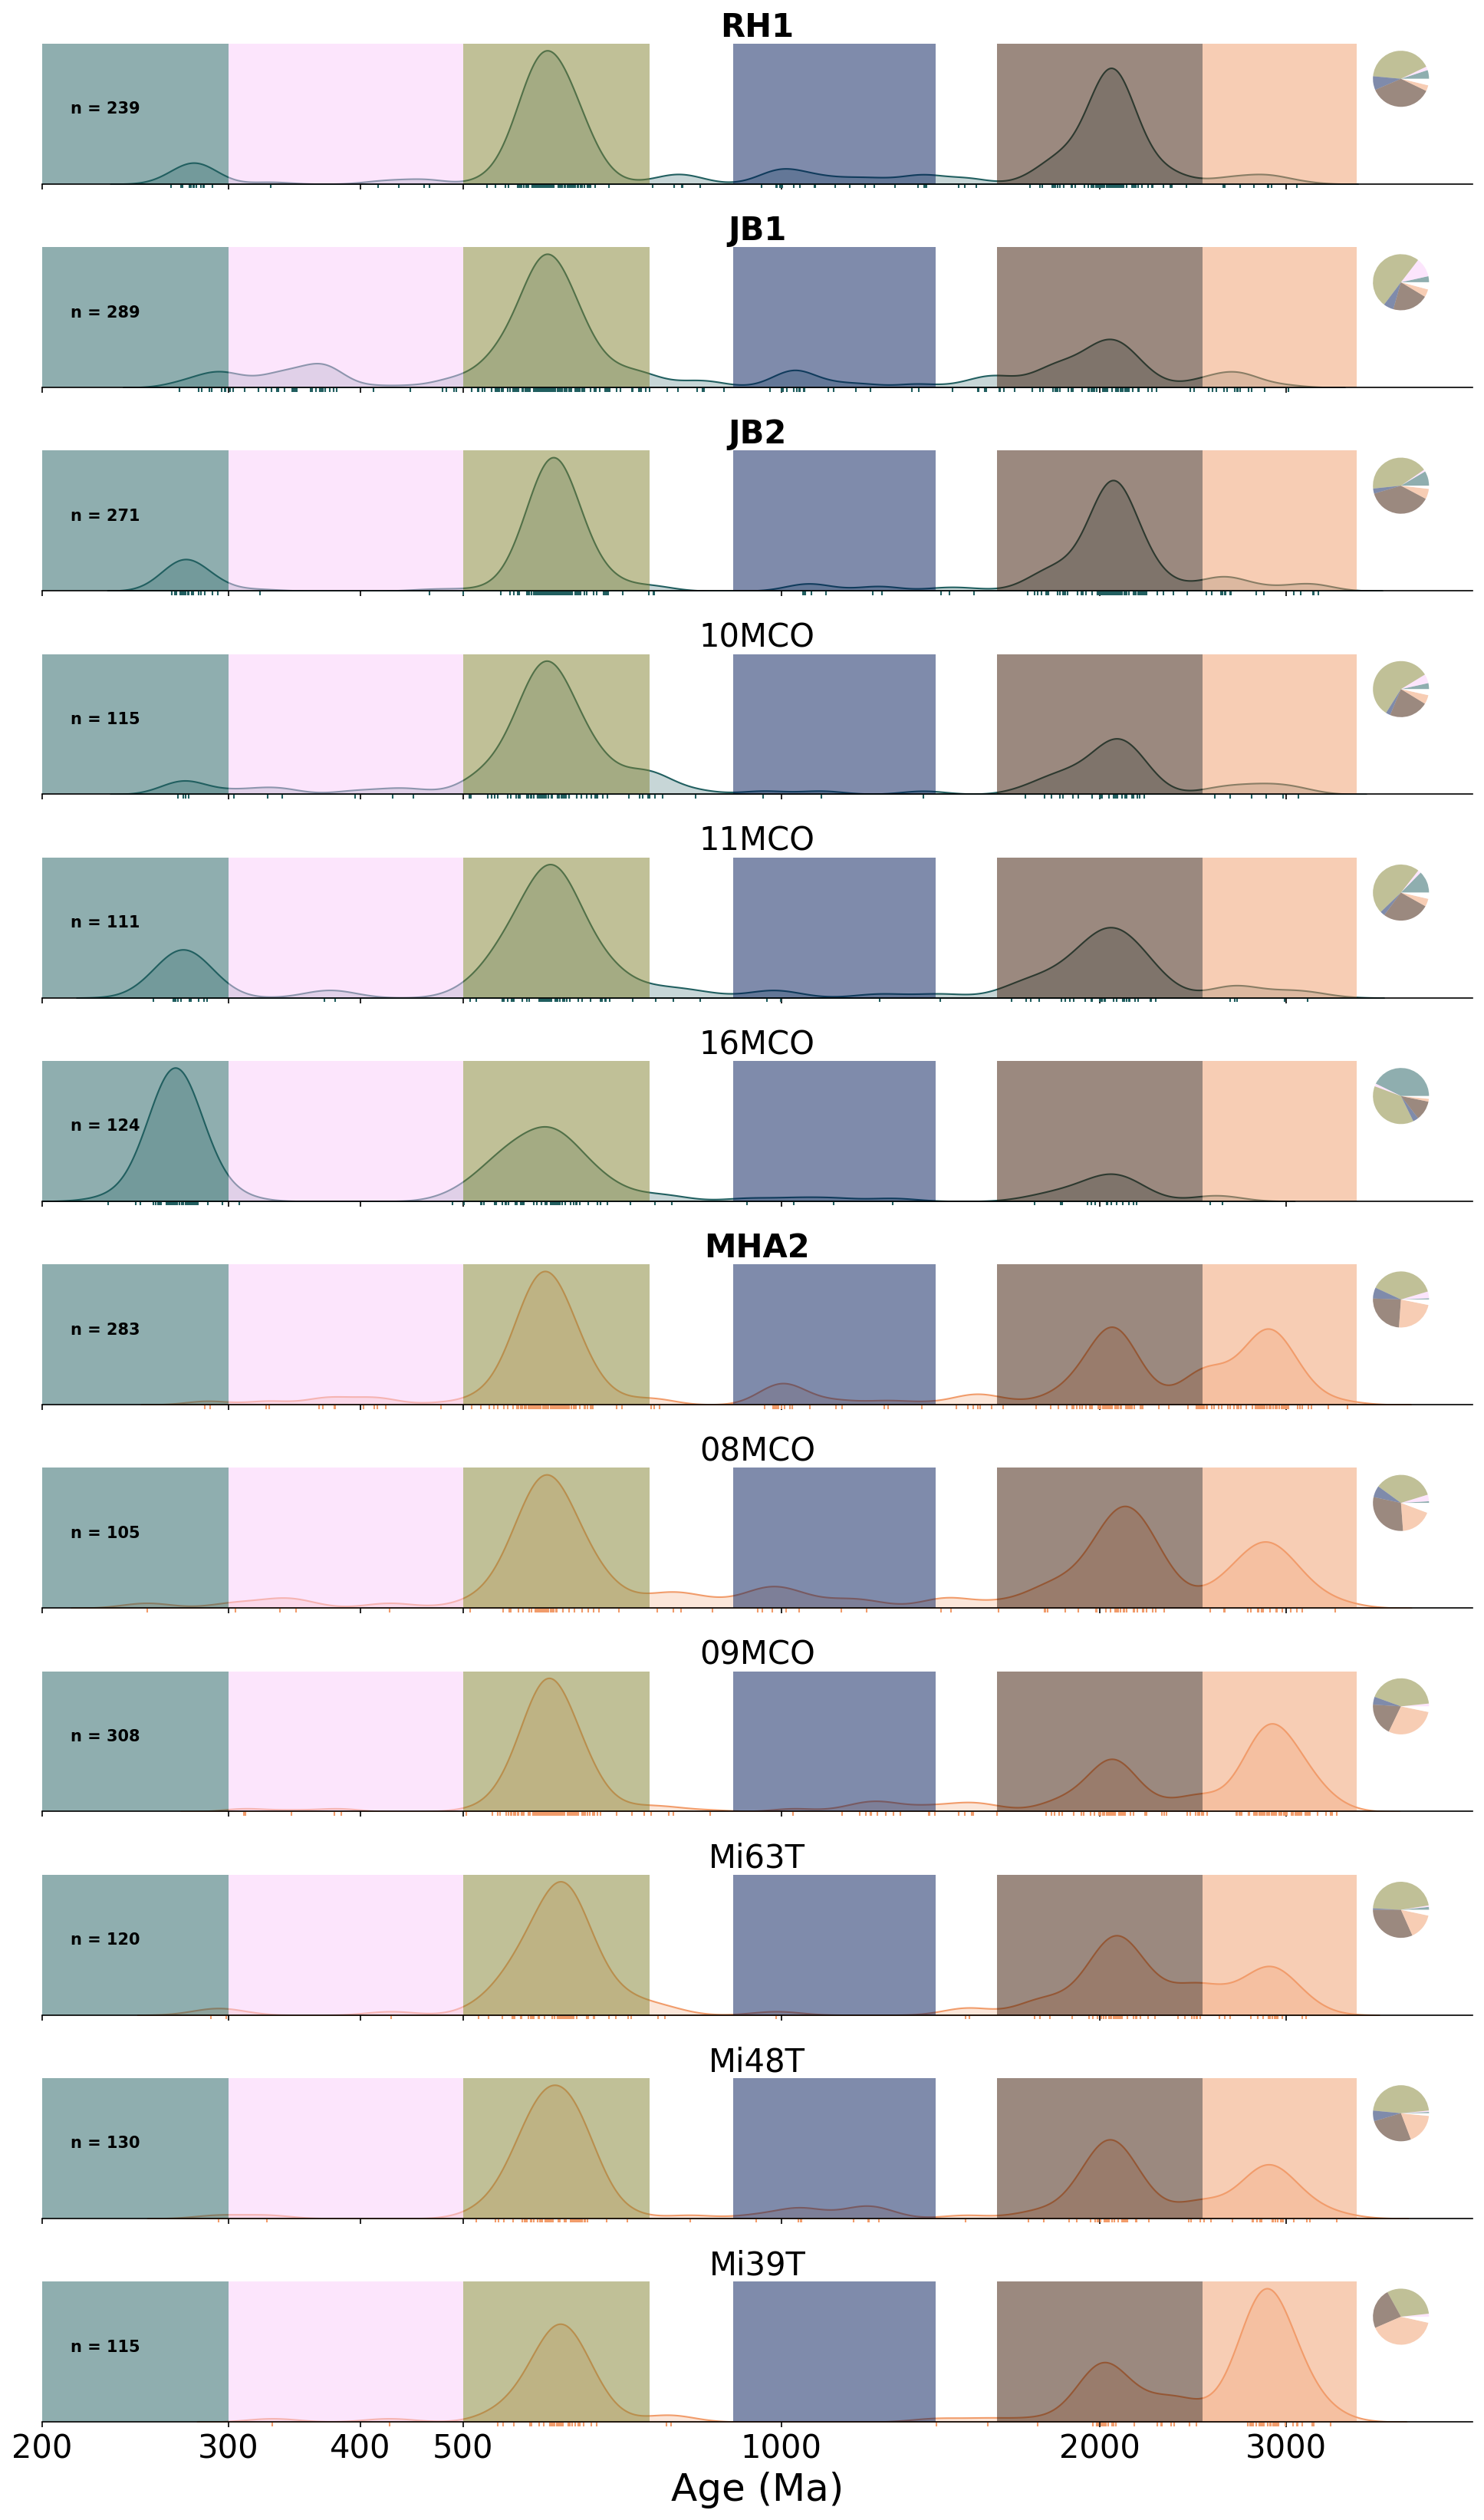

In [22]:
# Stacked KDEs of Meseta- and Reguibat-provenance samples (from analysis_dz.ipynb)
meseta = sorted([smp for smp in smps_ptr if smp.color==colors[0]],
                key=lambda smp: smp.latlon[0], reverse=True)
meseta[1], meseta[2] = meseta[2], meseta[1]
reguibat = sorted([smp for smp in smps_ptr if smp.color==colors[5]],
                  key=lambda smp: smp.latlon[0], reverse=True)

fig, axs = plt.subplots(len(meseta+reguibat), figsize=(13,22), dpi=150, sharex=True)

for ax, smp in zip(axs, meseta+reguibat):
    smp.kde(ax=ax, bw_adjust=0.2, spans=spans, span_colors=colors, add_pie=True)
    ax.set_title(mr24_dict.get(smp.name, smp.name), fontsize=fs-4, pad=2,
                 fontweight='bold' if smp.source=='Vasey' else 'normal')
    ax.set_xlim(200,4500)
    ax.set_xlabel(None)

axs[-1].set_xlabel('Age (Ma)', fontsize=fs)
axs[-1].tick_params(axis='x', labelsize=fs-4)

fig.tight_layout()
fig.savefig('agu_kdes.pdf')

/home/dyvasey/miniforge3/envs/dataset-morocco-dz-2024/lib/python3.11/site-packages/sklearn/manifold/_mds.py:677: FutureWarning: The default value of `n_init` will change from 4 to 1 in 1.9.
  warnings.warn(


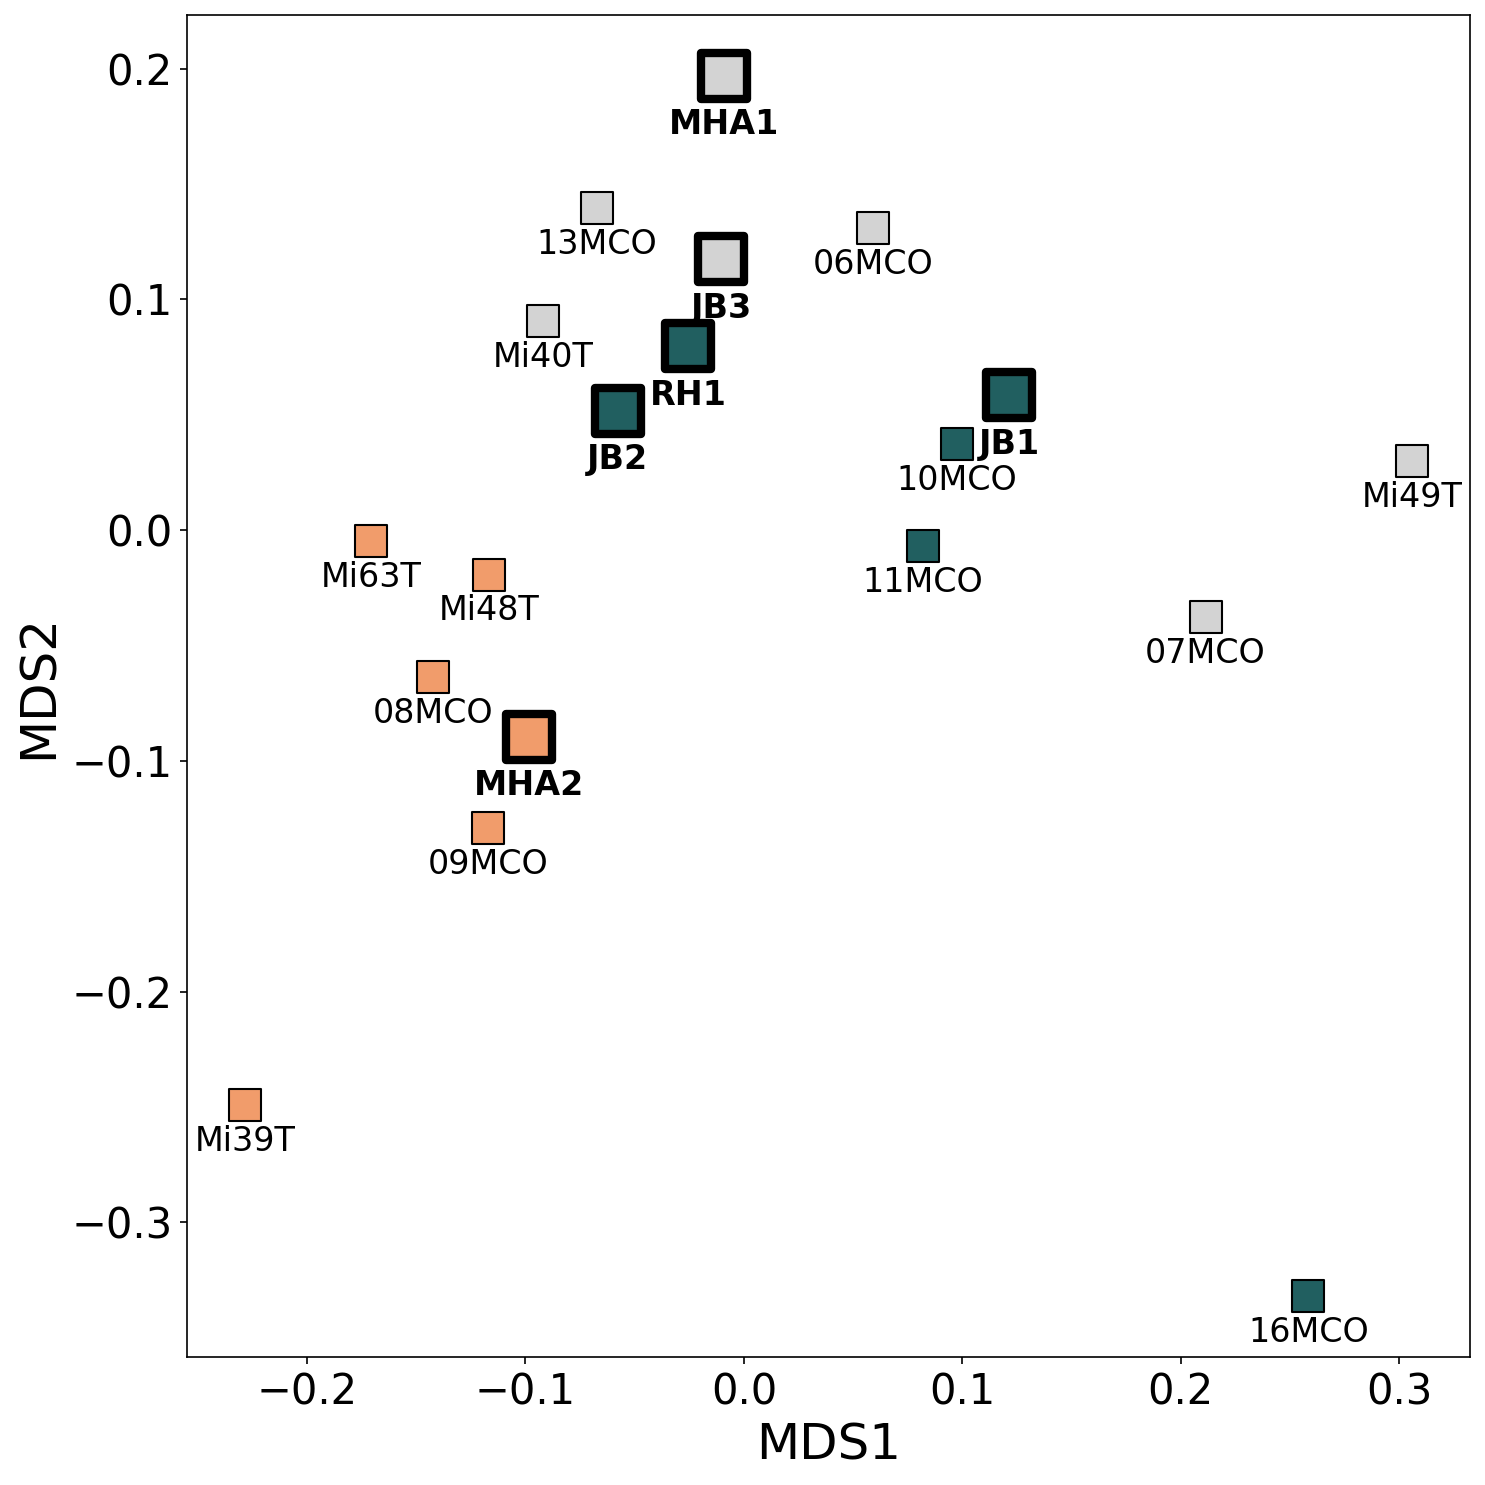

In [24]:
# MDS of detrital zircon samples using K-S distance (from analysis_dz.ipynb)


mds_smps = sorted(smps_ptr, key=lambda smp: smp.latlon[0], reverse=True)  # Same order as paper
dist_matrix = np.array([[ks_2samp(a.bestage, b.bestage)[0] for b in mds_smps] for a in mds_smps])
mds_matrix = MDS(n_components=2, dissimilarity='precomputed', random_state=172).fit_transform(dist_matrix)

fig, ax = plt.subplots(figsize=(10,10), dpi=150)

for (x, y), smp in zip(mds_matrix, mds_smps):
    new = smp.source=='Vasey'
    ax.scatter(x, y, color=smp.color, marker='s', edgecolor='black',
               linewidth=4 if new else 1, s=500 if new else 250, zorder=3)
    ax.annotate(mr24_dict.get(smp.name, smp.name), (x, y), xytext=(0, -28 if new else -22),
                textcoords='offset points', ha='center', fontsize=fs-8,
                fontweight='bold' if new else 'normal')

ax.tick_params(axis='both', labelsize=fs-4)
ax.set_xlabel('MDS1', fontsize=fs)
ax.set_ylabel('MDS2', fontsize=fs)

fig.tight_layout()
fig.savefig('agu_mds.pdf')